<a href="https://colab.research.google.com/github/pdf1802/f1-data-science/blob/main/telemetry_clash.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tool 5 — Telemetry Clash

**Goal:** Quantify *where on the circuit* one driver gains time over another, and *why* (braking later, more apex speed, earlier throttle).

**Inputs:** Two drivers' fastest qualifying laps from the same session.

**Pipeline:**
1. Load both laps → extract telemetry
2. Resample both onto a fixed distance grid (reuses Module 3 logic, extended for GPS)
3. Label corners using **curvature** of the GPS path
4. Compute speed/throttle/brake delta at every grid point
5. Overlay deltas on the circuit map → visual answer

**Validation pair:** Bahrain Q 2024, VER vs LEC.
Two very different driving styles (Module 3 placed them in separate clusters) on a circuit with a mix of slow hairpins (T10) and high-speed sections (T11–T12). Strong test case for whether the tool surfaces meaningful differences.

**Modules used:**
- Module 3 — `resample_to_distance_grid()` (extended)

**Models loaded:** None. This tool is pure telemetry analysis — no XGBoost predictions involved.

**Design note for future visual layer:** The corner-labeled GPS grid produced here is the same data structure the planned interactive race replay will need. Functions are written to be importable, not just inline-runnable.

In [ ]:
!pip install fastf1 --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.0/136.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 427.6/427.6 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.6 MB/s eta 0:00:00


In [ ]:
import fastf1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.interpolate import interp1d
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

CACHE_DIR = '/content/drive/MyDrive/f1_cache'
fastf1.Cache.enable_cache(CACHE_DIR)

print("Setup complete.")

Mounted at /content/drive
Setup complete.


## Step 1 — Load Session + Pick Fastest Laps

We use **fastest qualifying laps** because they isolate driver pace from confounders:
- No traffic (drivers go on cleared laps)
- No tyre degradation (single push lap on fresh Softs)
- No fuel variation (minimum fuel load by Q3)
- No team orders or strategy effects

Whatever delta we see between VER and LEC on these laps is *pure driver + car*, with car held constant by the circuit conditions. It's the cleanest signal F1 telemetry can give us.

**Critical check:** the FastF1 `X` and `Y` channels must be present and non-null. Tool 5 builds the entire circuit map from these. If they're missing, the rest of the notebook can't run.

In [ ]:
session = fastf1.get_session(2024, 'Bahrain', 'Q')
session.load()

ver_fastest_lap = session.laps.pick_driver('VER').pick_fastest()
lec_fastest_lap = session.laps.pick_driver('LEC').pick_fastest()

ver_tel = ver_fastest_lap.get_telemetry()
lec_tel = lec_fastest_lap.get_telemetry()

print(ver_fastest_lap)
print(lec_fastest_lap)
print(f"Delta(LEC-VER): {(lec_fastest_lap['LapTime'])- (ver_fastest_lap['LapTime'])}")

print(f"VER telemetry: {len(ver_tel)} points")
print(f"LEC telemetry: {len(lec_tel)} points")

print(ver_tel.columns)
print(lec_tel.columns)

for name, tel in [('VER', ver_tel), ('LEC', lec_tel)]:
    has_x = 'X' in tel.columns and tel['X'].notna().all()
    has_y = 'Y' in tel.columns and tel['Y'].notna().all()
    print(f"{name} — X usable: {has_x}, Y usable: {has_y}")

core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.8.3]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...
req         

Time                      0 days 01:14:03.304000
Driver                                       VER
DriverNumber                                   1
LapTime                   0 days 00:01:29.179000
LapNumber                                   16.0
Stint                                        6.0
PitOutTime                                   NaT
PitInTime                                    NaT
Sector1Time               0 days 00:00:28.535000
Sector2Time               0 days 00:00:38.269000
Sector3Time               0 days 00:00:22.375000
Sector1SessionTime        0 days 01:13:02.660000
Sector2SessionTime        0 days 01:13:40.929000
Sector3SessionTime        0 days 01:14:03.304000
SpeedI1                                    242.0
SpeedI2                                    271.0
SpeedFL                                    288.0
SpeedST                                    320.0
IsPersonalBest                              True
Compound                                    SOFT
TyreLife            

## Step 2 — Extend Module 3's Resampling to GPS

Module 3's `resample_to_distance_grid()` interpolates Speed, Throttle, Brake, DRS onto 300 evenly-spaced distance points. Tool 5 needs the same alignment for `X` and `Y` so we can compare both drivers at the same physical location on the circuit.

**Why interpolate GPS coordinates?**
The `X`/`Y` channel is sampled at the same irregular timestamps as everything else. VER has 702 telemetry points, LEC has 687 — they're at different positions on the track at the same array index. Without resampling onto a common distance grid, "index 100" means *different physical locations* for each driver, and any delta calculation is meaningless.

After resampling, grid index 100 → same percentage of the lap → same physical corner → meaningful comparison.

**Why this works geometrically:**
The GPS path between two consecutive samples is essentially a smooth arc at racing speeds. Linear interpolation between adjacent points introduces negligible error at 300 grid points (~17m spacing on a 5.4km lap). For corner detection we'll smooth further in cell 4.

In [ ]:
def resample_lap(tel,n_points = 300):
    """
    Extends Module 3's resample_to_distance_grid() to include GPS coordinates.

    Returns a DataFrame indexed by RelativeDistance (0 -> 1) with columns:
      Speed, Throttle, Brake, X, Y

    Future iterations could add nGear / RPM / Z (elevation) — they are
    already in the FastF1 telemetry and would be a one-line addition here.
    """

    grid = np.linspace(0, 1, n_points)
    channels = ['Speed', 'Throttle', 'Brake', 'X', 'Y']

    dist = tel['RelativeDistance'].values
    resampled = {}

    for channel in channels:
        values = tel[channel].astype(float).values
        f = interp1d(dist, values, bounds_error= False, fill_value= 'extrapolate')
        resampled[channel] = f(grid)

    return pd.DataFrame(resampled, index=grid)




ver_resampled = resample_lap(ver_tel)
lec_resampled = resample_lap(lec_tel)

print(f"VER shape: {ver_resampled.shape}")
print(f"LEC shape: {lec_resampled.shape}")

print(ver_resampled.head())
print(lec_resampled.head())


#Geometry sanity check
dx_start = ver_resampled.iloc[0]['X'] - lec_resampled.iloc[0]['X']
dy_start = ver_resampled.iloc[0]['Y'] - lec_resampled.iloc[0]['Y']
dist_start = np.sqrt(dx_start**2 + dy_start**2)

print(  f"Distance between first points: {dist_start}")


VER shape: (300, 5)
LEC shape: (300, 5)
               Speed  Throttle  Brake           X            Y
0.000000  297.236516     100.0    0.0 -375.535450  1370.085507
0.003344  300.326959     100.0    0.0 -368.094564  1532.873929
0.006689  301.636840     100.0    0.0 -360.063369  1712.275404
0.010033  303.974174     100.0    0.0 -352.055672  1892.149223
0.013378  307.340309     100.0    0.0 -344.759492  2071.737029
               Speed  Throttle  Brake           X            Y
0.000000  291.174782      99.0    0.0 -380.092874  1287.071740
0.003344  292.904859      99.0    0.0 -371.207965  1467.742665
0.006689  295.554280      99.0    0.0 -362.657296  1653.404341
0.010033  297.823448      99.0    0.0 -352.514720  1870.247024
0.013378  299.657669      99.0    0.0 -345.419655  2039.902295
Distance between first points: 83.13877362079388


## Step 3 — Detect Corners via GPS Curvature

A **corner** in geometric terms is a region of high path curvature. We use the actual GPS path of the cars to detect corners mathematically — no manual corner numbering, no hardcoded lap maps.

**Curvature formula** for a parametric path `(x(s), y(s))`:

$$\kappa(s) = \frac{|x'(s) \cdot y''(s) - y'(s) \cdot x''(s)|}{(x'(s)^2 + y'(s)^2)^{3/2}}$$

Where `'` is derivative with respect to grid index (which is uniform arc-length thanks to Step 2's resampling).

**Why an averaged path:** A single driver's racing line varies slightly corner-to-corner (apex hit, kerb usage). To get corner positions that are *property of the circuit, not of the driver*, we average VER's and LEC's GPS paths and detect curvature on that reference line.

**Why smooth first:** GPS data has small measurement jitter. Curvature is a *second derivative* operation, which amplifies noise dramatically. A light Gaussian smoothing on the position arrays kills the jitter without removing real corner geometry. We never trust raw second derivatives in DS — always smooth first.

**Why `find_peaks` over a threshold:** Curvature varies across the lap — Bahrain T1 is sharper than T11. A fixed threshold either misses gentle corners or merges sharp ones. `scipy.signal.find_peaks` with a *prominence* parameter is scale-relative: it finds local maxima that stand out from their surroundings regardless of absolute height.

**Bahrain reference:** the circuit has 15 numbered corners but several form sequences (T9–T10 chicane, T11–T12–T13 sweeping right). Expect curvature to detect ~10–13 peaks, with sequences appearing as single events — which is actually the right answer for time-loss analysis.

Corners detected: 9
Peak grid indices: [39, 83, 103, 123, 148, 190, 211, 226, 271]
As % of lap: ['13.0%', '27.7%', '34.3%', '41.0%', '49.3%', '63.3%', '70.3%', '75.3%', '90.3%']


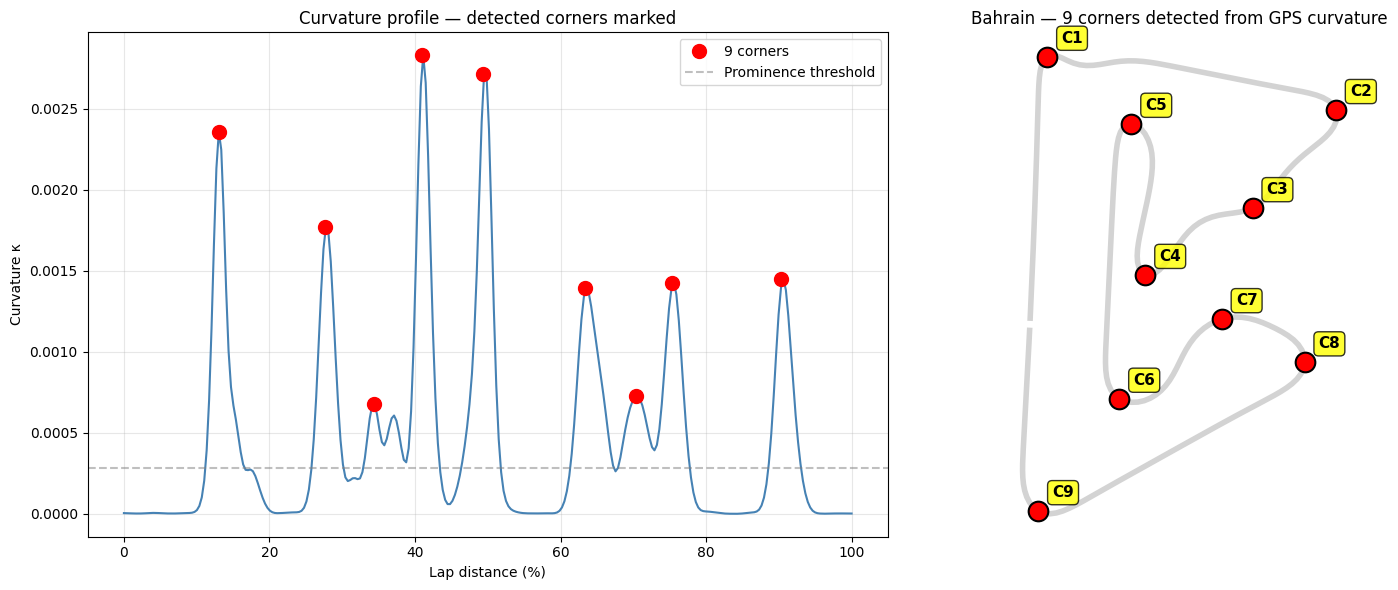

In [ ]:
from scipy.ndimage import gaussian_filter1d

ref_X = (ver_resampled['X'].values + lec_resampled['X'].values) / 2
ref_Y = (ver_resampled['Y'].values + lec_resampled['Y'].values) / 2


ref_X_smooth = gaussian_filter1d(ref_X, sigma=2)
ref_Y_smooth = gaussian_filter1d(ref_Y, sigma=2)

dx = np.gradient(ref_X_smooth)
dy = np.gradient(ref_Y_smooth)

ddx = np.gradient(dx)
ddy = np.gradient(dy)

numerator = np.abs(dx * ddy - dy * ddx)
denominator = np.sqrt((dx**2 + dy**2)**3) + 1e-9

curvature = numerator / denominator

curvature_smooth = gaussian_filter1d(curvature, sigma=2)

prominence_threshold = curvature_smooth.max() * 0.1
peaks, properties = find_peaks(
    curvature_smooth,
    prominence = prominence_threshold,
    distance=10

)

print(f"Corners detected: {len(peaks)}")
print(f"Peak grid indices: {peaks.tolist()}")
print(f"As % of lap: {[f'{p/300*100:.1f}%' for p in peaks]}")

#  Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (a) Curvature profile across the lap
axes[0].plot(np.linspace(0, 100, 300), curvature_smooth, color='steelblue', linewidth=1.5)
axes[0].plot(peaks/300*100, curvature_smooth[peaks], 'ro', markersize=10, label=f'{len(peaks)} corners')
axes[0].axhline(prominence_threshold, color='gray', linestyle='--', alpha=0.5, label='Prominence threshold')
axes[0].set_xlabel('Lap distance (%)')
axes[0].set_ylabel('Curvature κ')
axes[0].set_title('Curvature profile — detected corners marked')
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Circuit map with corner labels
axes[1].plot(ref_X_smooth, ref_Y_smooth, color='lightgray', linewidth=4, label='Racing line')
axes[1].scatter(ref_X_smooth[peaks], ref_Y_smooth[peaks],
                c='red', s=200, zorder=3, edgecolors='black', linewidth=1.5)
for i, p in enumerate(peaks):
    axes[1].annotate(f'C{i+1}', (ref_X_smooth[p], ref_Y_smooth[p]),
                     xytext=(10, 10), textcoords='offset points',
                     fontsize=11, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.3', fc='yellow', ec='black', alpha=0.8))
axes[1].set_aspect('equal')
axes[1].set_title(f'Bahrain — {len(peaks)} corners detected from GPS curvature')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## Step 4 — Compute the Delta and Visualise It

We finally compare VER and LEC directly. Two metrics:

**1. Speed delta (instantaneous)**
At each of the 300 grid points: `Δv = v_LEC - v_VER`. Positive means LEC is faster *at that physical location*. Useful for "where on the circuit does each driver shine?"

**2. Cumulative time delta (accumulated)**
Time to cover one segment ≈ segment_length / average_speed. We compute that for each driver per segment, take the difference, and **cumulatively sum**. This gives the running gap around the lap — exactly the curve you see on F1's official "Live Timing" telemetry overlay.

**Why cumulative matters more than instantaneous:**
A driver can be 5 km/h slower through a corner but already have a 0.1s buffer from the previous straight — they're still "winning" that segment in time terms. The instantaneous delta shows local style; the cumulative delta shows who's actually winning.

**Sanity check:** Our cumulative delta at lap end should approximately match the official lap time difference (LEC 0.014s faster). If we get a wildly different number (e.g., 0.5s), something is wrong with the unit conversion or segment-length calculation.

Predicted LEC gain: +16.5 ms
Actual LEC gain:    +14.0 ms
Reconstruction error: +2.51 ms



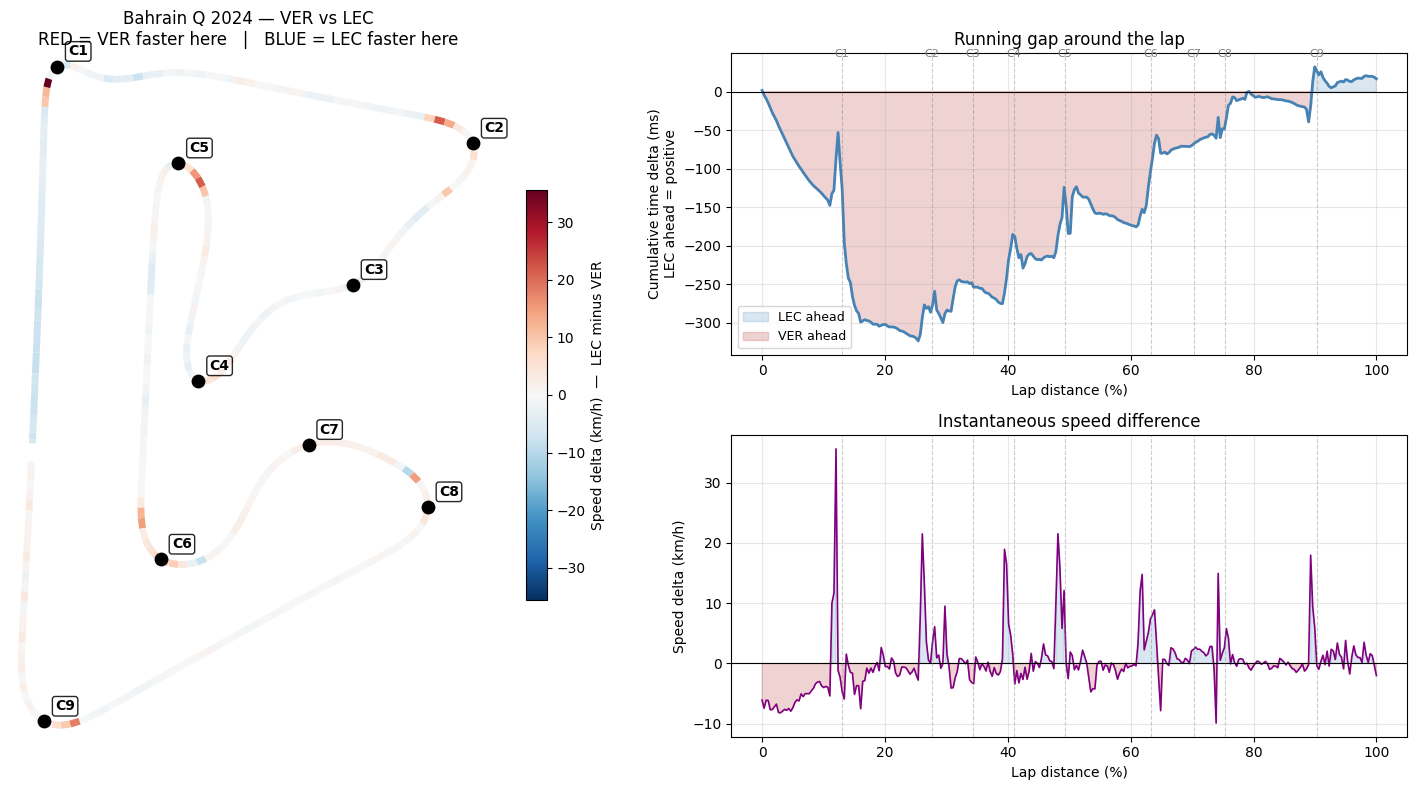

In [ ]:
# 1. Speed delta (instantaneous, no integration needed)
speed_delta = lec_resampled['Speed'].values - ver_resampled['Speed'].values

# 2. Cumulative time delta via FastF1's Time channel (exact)
grid_rd = np.linspace(0, 1, 300)

def resample_time(tel, grid_rd):
    """Resample elapsed time (seconds since lap start) onto the relative-distance grid."""
    t = (tel['Time'] - tel['Time'].iloc[0]).dt.total_seconds().values
    f = interp1d(tel['RelativeDistance'].values, t,
                 bounds_error=False, fill_value='extrapolate')
    return f(grid_rd)

ver_time = resample_time(ver_tel, grid_rd)
lec_time = resample_time(lec_tel, grid_rd)

# Positive = LEC ahead (took less time to reach this point on the lap)
cumulative_dt = ver_time - lec_time

# Sanity check
predicted_total_ms = cumulative_dt[-1] * 1000
actual_total_ms    = (ver_fastest_lap['LapTime'] - lec_fastest_lap['LapTime']).total_seconds() * 1000
print(f"Predicted LEC gain: {predicted_total_ms:+.1f} ms")
print(f"Actual LEC gain:    {actual_total_ms:+.1f} ms")
print(f"Reconstruction error: {predicted_total_ms - actual_total_ms:+.2f} ms\n")

# === 3. Visualisation ===
fig = plt.figure(figsize=(16, 8))
gs  = fig.add_gridspec(2, 2, height_ratios=[1, 1], width_ratios=[1.2, 1])

# (a) Circuit map coloured by speed delta
ax_map = fig.add_subplot(gs[:, 0])
points   = np.array([ref_X_smooth, ref_Y_smooth]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
max_abs  = np.abs(speed_delta).max()
lc = LineCollection(segments, cmap='RdBu_r',
                    norm=plt.Normalize(-max_abs, max_abs), linewidth=5)
lc.set_array(speed_delta[:-1])
ax_map.add_collection(lc)
ax_map.set_xlim(ref_X_smooth.min() - 200, ref_X_smooth.max() + 200)
ax_map.set_ylim(ref_Y_smooth.min() - 200, ref_Y_smooth.max() + 200)

ax_map.scatter(ref_X_smooth[peaks], ref_Y_smooth[peaks],
               c='black', s=80, zorder=3)
for i, p in enumerate(peaks):
    ax_map.annotate(f'C{i+1}', (ref_X_smooth[p], ref_Y_smooth[p]),
                    xytext=(8, 8), textcoords='offset points',
                    fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='black', alpha=0.85))

ax_map.set_aspect('equal'); ax_map.axis('off')
ax_map.set_title('Bahrain Q 2024 — VER vs LEC\nRED = VER faster here   |   BLUE = LEC faster here',
                 fontsize=12)
plt.colorbar(lc, ax=ax_map, shrink=0.6, label='Speed delta (km/h)  —  LEC minus VER')

# (b) Cumulative time delta — now length 300, not 299
ax_time = fig.add_subplot(gs[0, 1])
x_axis_300 = np.linspace(0, 100, 300)
ax_time.plot(x_axis_300, cumulative_dt * 1000, color='steelblue', linewidth=2)
ax_time.axhline(0, color='black', linewidth=0.8)
ax_time.fill_between(x_axis_300, 0, cumulative_dt * 1000,
                     where=(cumulative_dt > 0), color='steelblue', alpha=0.2, label='LEC ahead')
ax_time.fill_between(x_axis_300, 0, cumulative_dt * 1000,
                     where=(cumulative_dt < 0), color='firebrick', alpha=0.2, label='VER ahead')
for i, p in enumerate(peaks):
    ax_time.axvline(p/300*100, color='gray', linestyle='--', alpha=0.4, linewidth=0.8)
    ax_time.text(p/300*100, ax_time.get_ylim()[1]*0.9, f'C{i+1}',
                 fontsize=8, ha='center', color='gray')
ax_time.set_xlabel('Lap distance (%)')
ax_time.set_ylabel('Cumulative time delta (ms)\nLEC ahead = positive')
ax_time.set_title('Running gap around the lap')
ax_time.legend(loc='best', fontsize=9)
ax_time.grid(alpha=0.3)

# (c) Speed delta profile
ax_speed = fig.add_subplot(gs[1, 1])
ax_speed.plot(np.linspace(0, 100, 300), speed_delta, color='purple', linewidth=1.2)
ax_speed.axhline(0, color='black', linewidth=0.8)
ax_speed.fill_between(np.linspace(0, 100, 300), 0, speed_delta,
                      where=(speed_delta > 0), color='steelblue', alpha=0.2)
ax_speed.fill_between(np.linspace(0, 100, 300), 0, speed_delta,
                      where=(speed_delta < 0), color='firebrick', alpha=0.2)
for i, p in enumerate(peaks):
    ax_speed.axvline(p/300*100, color='gray', linestyle='--', alpha=0.4, linewidth=0.8)
ax_speed.set_xlabel('Lap distance (%)')
ax_speed.set_ylabel('Speed delta (km/h)')
ax_speed.set_title('Instantaneous speed difference')
ax_speed.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 5 — Wrap Into a Reusable API

Everything above ran for one hardcoded pair (Bahrain, VER, LEC). To make Tool 5 a real tool — and to feed the planned circuit-replay layer — we refactor into clean functions with a clear contract:

**Compute functions** (return data, no plotting):
- `resample_lap()` — telemetry → distance grid *(already defined above)*
- `detect_corners()` — averaged GPS path → corner indices + reference line
- `compute_deltas()` — two grids → speed delta + cumulative time delta
- `compare_drivers()` — the orchestrator: takes (year, gp, session, driver_a, driver_b), returns a single results dict

**Visualization function** (takes data, draws):
- `plot_clash()` — results dict → the 3-panel figure

**Why separate compute from plot?** The future Streamlit/replay layer will call the compute functions and render its own interactive UI. It should never have to import matplotlib or untangle plotting code to get the numbers. This is the same clean-API discipline that let Tool 5 reuse Module 3's resampler in one line.

In [ ]:
def detect_corners(grid_a, grid_b, sigma=2, prominence_frac=0.1, min_distance=10):
    """
    Detect corners from the averaged GPS path via curvature peak detection.

    Averaging both drivers' lines gives a reference path that is a property
    of the circuit, not of one driver's racing line.

    Returns dict:
      peaks        : np.array of grid indices where corners are
      ref_X_smooth : smoothed reference-line X (for plotting)
      ref_Y_smooth : smoothed reference-line Y
      curvature    : smoothed curvature profile
    """
    ref_X = (grid_a['X'].values + grid_b['X'].values) / 2
    ref_Y = (grid_a['Y'].values + grid_b['Y'].values) / 2

    ref_X_smooth = gaussian_filter1d(ref_X, sigma=sigma)
    ref_Y_smooth = gaussian_filter1d(ref_Y, sigma=sigma)

    dx, dy   = np.gradient(ref_X_smooth), np.gradient(ref_Y_smooth)
    ddx, ddy = np.gradient(dx), np.gradient(dy)

    numerator   = np.abs(dx * ddy - dy * ddx)
    denominator = np.sqrt((dx**2 + dy**2)**3) + 1e-9
    curvature   = gaussian_filter1d(numerator / denominator, sigma=sigma)

    peaks, _ = find_peaks(curvature,
                          prominence=curvature.max() * prominence_frac,
                          distance=min_distance)

    return {
        'peaks': peaks,
        'ref_X_smooth': ref_X_smooth,
        'ref_Y_smooth': ref_Y_smooth,
        'curvature': curvature,
    }


def compute_deltas(grid_a, grid_b, tel_a, tel_b, n_points=300):
    """
    Compute speed delta (instantaneous) and cumulative time delta (exact,
    via FastF1's Time channel — no numerical integration).

    Sign convention: positive means driver B is faster / ahead.

    Returns dict:
      speed_delta   : np.array (B minus A, km/h)
      cumulative_dt : np.array (seconds, B ahead = positive)
      total_dt_ms   : float, final gap in milliseconds
    """
    grid = np.linspace(0, 1, n_points)

    speed_delta = grid_b['Speed'].values - grid_a['Speed'].values

    def resample_time(tel):
        t = (tel['Time'] - tel['Time'].iloc[0]).dt.total_seconds().values
        f = interp1d(tel['RelativeDistance'].values, t,
                     bounds_error=False, fill_value='extrapolate')
        return f(grid)

    # A took longer to reach this point => B is ahead => positive
    cumulative_dt = resample_time(tel_a) - resample_time(tel_b)

    return {
        'speed_delta': speed_delta,
        'cumulative_dt': cumulative_dt,
        'total_dt_ms': cumulative_dt[-1] * 1000,
    }


def compare_drivers(year, gp, session_type, driver_a, driver_b, n_points=300):
    """
    Full Tool 5 pipeline for any session and driver pair.

    Sign convention throughout: positive deltas mean driver_b is faster/ahead.

    Returns a results dict bundling everything the visual layer needs:
      meta, laps, grids, corners, deltas, validation.
    """
    session = fastf1.get_session(year, gp, session_type)
    session.load()

    lap_a = session.laps.pick_driver(driver_a).pick_fastest()
    lap_b = session.laps.pick_driver(driver_b).pick_fastest()
    tel_a = lap_a.get_telemetry()
    tel_b = lap_b.get_telemetry()

    grid_a = resample_lap(tel_a, n_points)
    grid_b = resample_lap(tel_b, n_points)

    corners = detect_corners(grid_a, grid_b)
    deltas  = compute_deltas(grid_a, grid_b, tel_a, tel_b, n_points)

    actual_dt_ms = (lap_a['LapTime'] - lap_b['LapTime']).total_seconds() * 1000

    return {
        'meta': {
            'year': year, 'gp': gp, 'session': session_type,
            'driver_a': driver_a, 'driver_b': driver_b,
            'event_name': session.event['EventName'],
            'lap_length_m': (tel_a['Distance'].max() + tel_b['Distance'].max()) / 2,
        },
        'laps':   {'a': lap_a, 'b': lap_b},
        'grids':  {'a': grid_a, 'b': grid_b},
        'corners': corners,
        'deltas':  deltas,
        'validation': {
            'predicted_dt_ms': deltas['total_dt_ms'],
            'actual_dt_ms':    actual_dt_ms,
            'error_ms':        deltas['total_dt_ms'] - actual_dt_ms,
        },
    }


print("Tool 5 API defined: compare_drivers(), detect_corners(), compute_deltas()")

Tool 5 API defined: compare_drivers(), detect_corners(), compute_deltas()


In [ ]:
def plot_clash(results, figsize=(16, 8)):
    """
    Render the 3-panel Tool 5 figure from a compare_drivers() results dict.

    Panels:
      (a) Circuit map coloured by speed delta, corners marked
      (b) Cumulative time delta around the lap
      (c) Instantaneous speed delta profile

    Colour convention: RED = driver_a faster, BLUE = driver_b faster.
    """
    meta    = results['meta']
    corners = results['corners']
    deltas  = results['deltas']
    val     = results['validation']

    a, b = meta['driver_a'], meta['driver_b']
    peaks        = corners['peaks']
    ref_X_smooth = corners['ref_X_smooth']
    ref_Y_smooth = corners['ref_Y_smooth']
    speed_delta   = deltas['speed_delta']
    cumulative_dt = deltas['cumulative_dt']

    n_points = len(speed_delta)
    x_axis   = np.linspace(0, 100, n_points)

    fig = plt.figure(figsize=figsize)
    gs  = fig.add_gridspec(2, 2, height_ratios=[1, 1], width_ratios=[1.2, 1])

    # --- (a) Circuit map coloured by speed delta ---
    ax_map = fig.add_subplot(gs[:, 0])
    points   = np.array([ref_X_smooth, ref_Y_smooth]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    max_abs  = np.abs(speed_delta).max()

    lc = LineCollection(segments, cmap='RdBu_r',
                        norm=plt.Normalize(-max_abs, max_abs), linewidth=5)
    lc.set_array(speed_delta[:-1])
    ax_map.add_collection(lc)
    ax_map.set_xlim(ref_X_smooth.min() - 200, ref_X_smooth.max() + 200)
    ax_map.set_ylim(ref_Y_smooth.min() - 200, ref_Y_smooth.max() + 200)

    ax_map.scatter(ref_X_smooth[peaks], ref_Y_smooth[peaks],
                   c='black', s=80, zorder=3)
    for i, p in enumerate(peaks):
        ax_map.annotate(f'C{i+1}', (ref_X_smooth[p], ref_Y_smooth[p]),
                        xytext=(8, 8), textcoords='offset points',
                        fontsize=10, fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.2', fc='white',
                                  ec='black', alpha=0.85))

    ax_map.set_aspect('equal')
    ax_map.axis('off')
    ax_map.set_title(
        f"{meta['event_name']} {meta['year']} {meta['session']} — {a} vs {b}\n"
        f"RED = {a} faster here   |   BLUE = {b} faster here",
        fontsize=12)
    plt.colorbar(lc, ax=ax_map, shrink=0.6,
                 label=f'Speed delta (km/h) — {b} minus {a}')

    # --- (b) Cumulative time delta ---
    ax_time = fig.add_subplot(gs[0, 1])
    ax_time.plot(x_axis, cumulative_dt * 1000, color='steelblue', linewidth=2)
    ax_time.axhline(0, color='black', linewidth=0.8)
    ax_time.fill_between(x_axis, 0, cumulative_dt * 1000,
                         where=(cumulative_dt > 0), color='steelblue',
                         alpha=0.2, label=f'{b} ahead')
    ax_time.fill_between(x_axis, 0, cumulative_dt * 1000,
                         where=(cumulative_dt < 0), color='firebrick',
                         alpha=0.2, label=f'{a} ahead')
    for i, p in enumerate(peaks):
        ax_time.axvline(p / n_points * 100, color='gray',
                        linestyle='--', alpha=0.4, linewidth=0.8)
        ax_time.text(p / n_points * 100, ax_time.get_ylim()[1] * 0.9,
                     f'C{i+1}', fontsize=8, ha='center', color='gray')
    ax_time.set_xlabel('Lap distance (%)')
    ax_time.set_ylabel(f'Cumulative time delta (ms)\n{b} ahead = positive')
    ax_time.set_title(
        f"Running gap — final: {val['predicted_dt_ms']:+.0f} ms "
        f"(actual {val['actual_dt_ms']:+.0f} ms, err {val['error_ms']:+.1f} ms)",
        fontsize=10)
    ax_time.legend(loc='best', fontsize=9)
    ax_time.grid(alpha=0.3)

    # --- (c) Speed delta profile ---
    ax_speed = fig.add_subplot(gs[1, 1])
    ax_speed.plot(x_axis, speed_delta, color='purple', linewidth=1.2)
    ax_speed.axhline(0, color='black', linewidth=0.8)
    ax_speed.fill_between(x_axis, 0, speed_delta,
                          where=(speed_delta > 0), color='steelblue', alpha=0.2)
    ax_speed.fill_between(x_axis, 0, speed_delta,
                          where=(speed_delta < 0), color='firebrick', alpha=0.2)
    for p in peaks:
        ax_speed.axvline(p / n_points * 100, color='gray',
                         linestyle='--', alpha=0.4, linewidth=0.8)
    ax_speed.set_xlabel('Lap distance (%)')
    ax_speed.set_ylabel('Speed delta (km/h)')
    ax_speed.set_title('Instantaneous speed difference')
    ax_speed.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return fig


print("plot_clash() defined.")

plot_clash() defined.


core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.8.3]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...
req         

Predicted LEC gain: +16.5 ms
Actual gap:                +14.0 ms
Reconstruction error:      +2.51 ms
Corners detected:          9


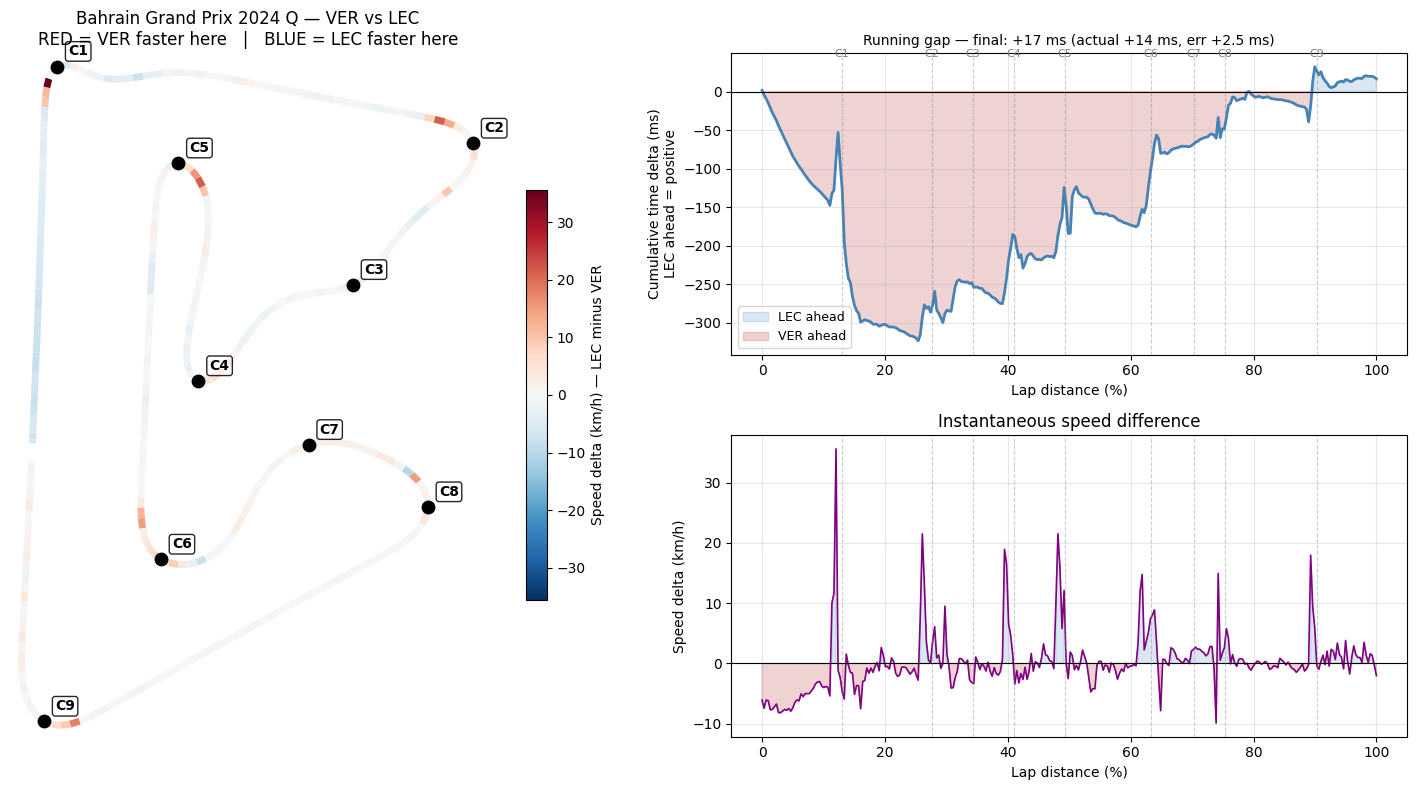

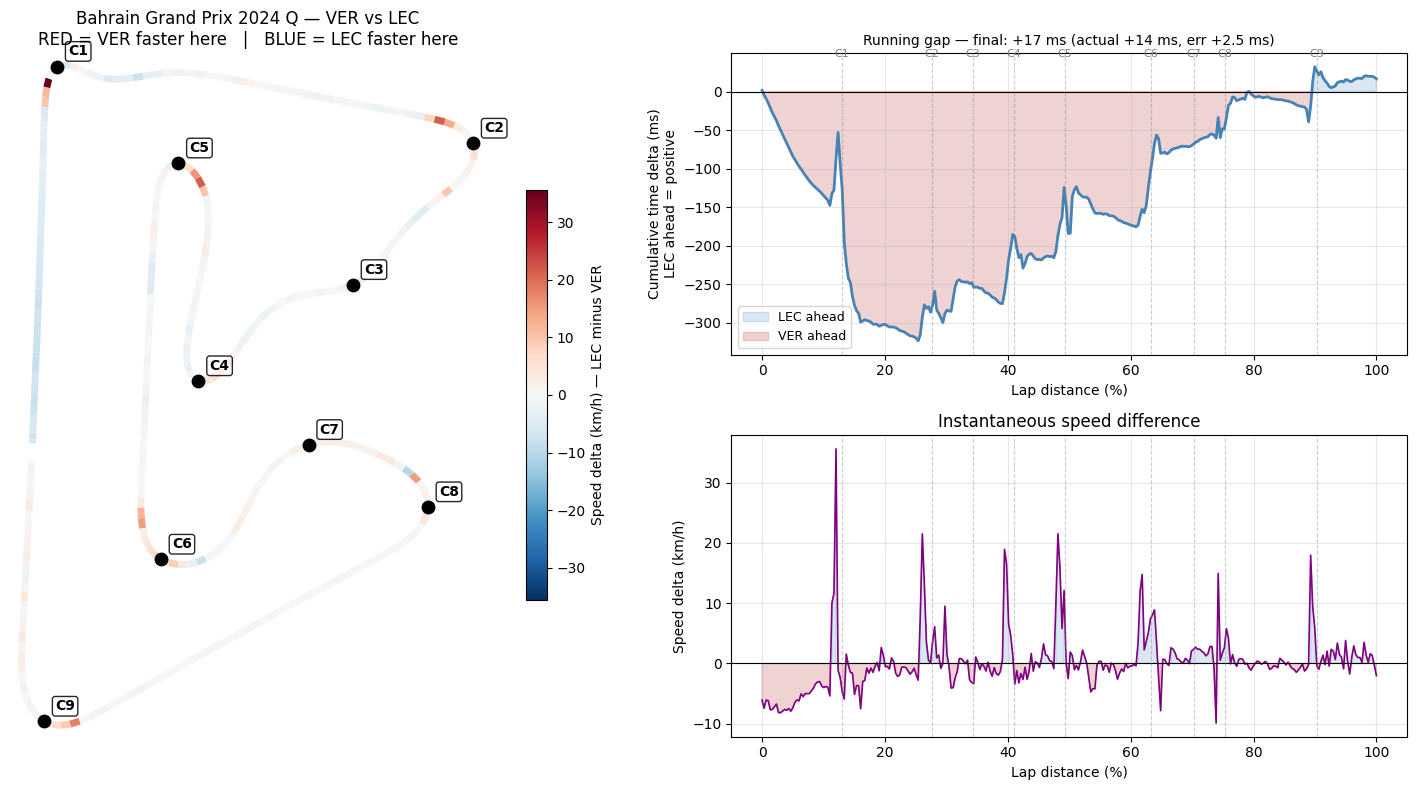

In [ ]:
# Reproduce the original analysis through the new API
results = compare_drivers(2024, 'Bahrain', 'Q', 'VER', 'LEC')

print(f"Predicted {results['meta']['driver_b']} gain: "
      f"{results['validation']['predicted_dt_ms']:+.1f} ms")
print(f"Actual gap:                {results['validation']['actual_dt_ms']:+.1f} ms")
print(f"Reconstruction error:      {results['validation']['error_ms']:+.2f} ms")
print(f"Corners detected:          {len(results['corners']['peaks'])}")

plot_clash(results)

## Step 6 — Per-Corner Diagnostics

The speed delta tells us *where* one driver is faster. It doesn't tell us *why*. Three mechanisms produce a corner time gain, and they're physically distinct:

1. **Later braking** — delaying the brake point carries more speed into the corner
2. **Higher apex speed** — more minimum speed through the corner itself (mechanical grip, line, confidence)
3. **Earlier throttle** — getting back to power sooner on exit

A driver can gain through any one of these, and they trade off against each other — braking later usually *costs* apex speed, because the car arrives at the apex unsettled. Separating them is what turns "LEC was faster at C9" into "LEC was faster at C9 *because* he braked 12m later and still matched apex speed."

**Corner zones:** each corner gets a window around its curvature peak, bounded by the midpoint to its neighbours so zones never overlap. Within each zone we measure apex speed, brake point (distance before apex), throttle-on point (distance after apex), and the net time gained across the zone.

In [ ]:
def analyze_corners(results, max_half_width=12, brake_thresh=0.5, throttle_thresh=90):
    """
    Per-corner diagnostic breakdown from a compare_drivers() results dict.

    For each detected corner, measures for both drivers:
      - apex speed (minimum speed in the corner zone)
      - brake point (metres before apex where brake is first applied)
      - throttle-on point (metres after apex where throttle exceeds threshold)
      - net time gained by driver B across the zone

    Returns a pandas DataFrame, one row per corner.
    """
    meta    = results['meta']
    peaks   = results['corners']['peaks']
    grid_a, grid_b = results['grids']['a'], results['grids']['b']
    cum_dt  = results['deltas']['cumulative_dt']
    a, b    = meta['driver_a'], meta['driver_b']

    n_points = len(cum_dt)
    mpp = meta['lap_length_m'] / (n_points - 1)   # metres per grid point

    spd_a, spd_b = grid_a['Speed'].values, grid_b['Speed'].values
    brk_a, brk_b = grid_a['Brake'].values, grid_b['Brake'].values
    thr_a, thr_b = grid_a['Throttle'].values, grid_b['Throttle'].values

    def brake_point_m(brake, left, apex):
        """Metres before apex where brake first exceeds threshold. NaN if flat-out."""
        window = np.where(brake[left:apex] > brake_thresh)[0]
        return (apex - (left + window[0])) * mpp if len(window) else np.nan

    def throttle_point_m(throttle, apex, right):
        """Metres after apex where throttle first exceeds threshold. NaN if never."""
        window = np.where(throttle[apex:right] > throttle_thresh)[0]
        return window[0] * mpp if len(window) else np.nan

    rows = []
    for i, p in enumerate(peaks):
        # Zone bounded by midpoints to neighbours, capped at max_half_width
        prev_gap = p - peaks[i-1] if i > 0 else max_half_width * 2
        next_gap = peaks[i+1] - p if i < len(peaks) - 1 else max_half_width * 2
        left  = max(0, p - min(max_half_width, prev_gap // 2))
        right = min(n_points - 1, p + min(max_half_width, next_gap // 2))

        apex_a = left + int(np.argmin(spd_a[left:right]))
        apex_b = left + int(np.argmin(spd_b[left:right]))

        bp_a = brake_point_m(brk_a, left, apex_a)
        bp_b = brake_point_m(brk_b, left, apex_b)
        tp_a = throttle_point_m(thr_a, apex_a, right)
        tp_b = throttle_point_m(thr_b, apex_b, right)

        rows.append({
            'Corner':          f'C{i+1}',
            'Lap%':            round(p / n_points * 100, 1),
            f'Apex_{a}':       round(spd_a[apex_a], 1),
            f'Apex_{b}':       round(spd_b[apex_b], 1),
            'dApex':           round(spd_b[apex_b] - spd_a[apex_a], 1),
            f'Brake_{a}_m':    round(bp_a, 1) if not np.isnan(bp_a) else np.nan,
            f'Brake_{b}_m':    round(bp_b, 1) if not np.isnan(bp_b) else np.nan,
            'dBrake_m':        round(bp_a - bp_b, 1) if not (np.isnan(bp_a) or np.isnan(bp_b)) else np.nan,
            f'Thr_{a}_m':      round(tp_a, 1) if not np.isnan(tp_a) else np.nan,
            f'Thr_{b}_m':      round(tp_b, 1) if not np.isnan(tp_b) else np.nan,
            'dThr_m':          round(tp_a - tp_b, 1) if not (np.isnan(tp_a) or np.isnan(tp_b)) else np.nan,
            'TimeGain_ms':     round((cum_dt[right] - cum_dt[left]) * 1000, 1),
        })

    return pd.DataFrame(rows)


corner_table = analyze_corners(results)

a, b = results['meta']['driver_a'], results['meta']['driver_b']
print(f"Per-corner diagnostics — positive values favour {b}\n")
print(f"  dApex     : {b} carries more apex speed (km/h)")
print(f"  dBrake_m  : {b} brakes later (metres)")
print(f"  dThr_m    : {b} gets on throttle earlier (metres)")
print(f"  TimeGain  : net ms {b} gained across the corner zone\n")

display(corner_table)

Per-corner diagnostics — positive values favour LEC

  dApex     : LEC carries more apex speed (km/h)
  dBrake_m  : LEC brakes later (metres)
  dThr_m    : LEC gets on throttle earlier (metres)
  TimeGain  : net ms LEC gained across the corner zone



,Corner,Lap%,Apex_VER,Apex_LEC,dApex,Brake_VER_m,Brake_LEC_m,dBrake_m,Thr_VER_m,Thr_LEC_m,dThr_m,TimeGain_ms
0,C1,13.0,71.4,65.5,-5.9,125.8,197.7,-71.9,89.9,125.8,-35.9,-170.0
1,C2,27.7,120.9,127.0,6.1,107.8,107.8,0.0,71.9,71.9,0.0,46.6
2,C3,34.3,218.4,219.0,0.6,71.9,NaN,NaN,18.0,0.0,18.0,0.7
3,C4,41.0,81.5,80.4,-1.2,125.8,107.8,18.0,53.9,53.9,0.0,50.1
4,C5,49.3,79.6,80.5,0.9,107.8,107.8,0.0,53.9,71.9,-18.0,72.7
5,C6,63.3,163.9,172.5,8.6,125.8,89.9,35.9,35.9,53.9,-18.0,97.0
6,C7,70.3,236.9,238.7,1.8,NaN,NaN,NaN,0.0,0.0,0.0,18.0
7,C8,75.3,141.3,147.1,5.8,107.8,107.8,0.0,53.9,71.9,-18.0,51.5
8,C9,90.3,135.0,134.1,-1.0,107.8,71.9,35.9,53.9,53.9,0.0,27.9


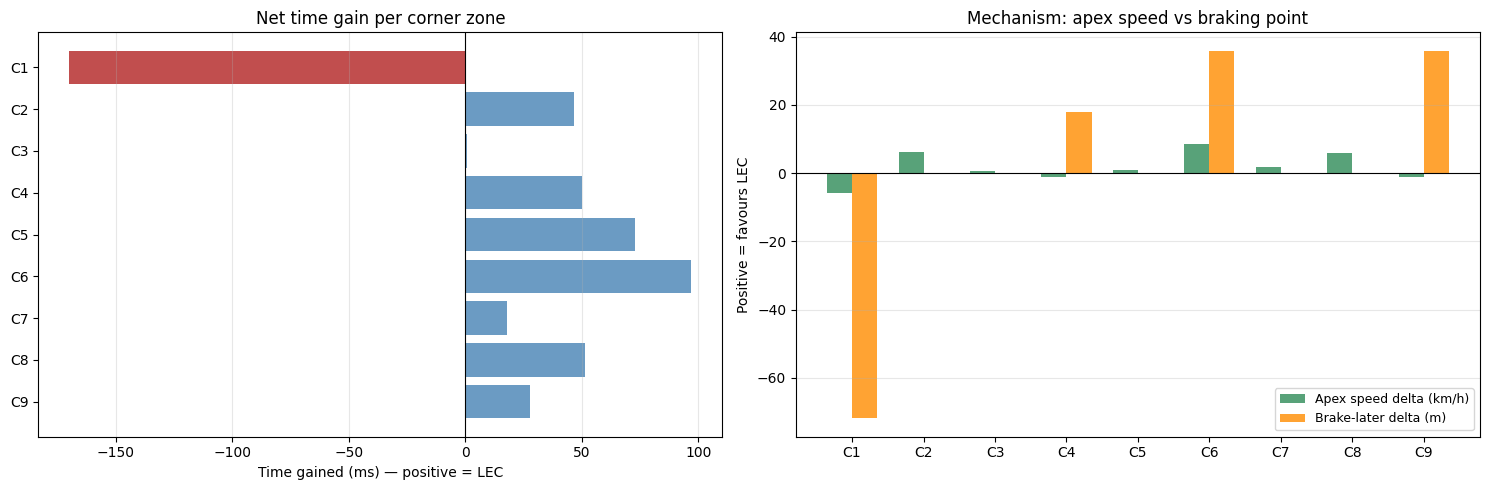

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = ['steelblue' if v > 0 else 'firebrick' for v in corner_table['TimeGain_ms']]

# (a) Net time gain per corner
axes[0].barh(corner_table['Corner'], corner_table['TimeGain_ms'], color=colors, alpha=0.8)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_xlabel(f'Time gained (ms) — positive = {b}')
axes[0].set_title(f'Net time gain per corner zone')
axes[0].invert_yaxis()
axes[0].grid(alpha=0.3, axis='x')

# (b) Mechanism breakdown — apex speed vs brake point
x = np.arange(len(corner_table))
width = 0.35
axes[1].bar(x - width/2, corner_table['dApex'], width,
            label='Apex speed delta (km/h)', color='seagreen', alpha=0.8)
axes[1].bar(x + width/2, corner_table['dBrake_m'], width,
            label='Brake-later delta (m)', color='darkorange', alpha=0.8)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(corner_table['Corner'])
axes[1].set_ylabel(f'Positive = favours {b}')
axes[1].set_title('Mechanism: apex speed vs braking point')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# --- 1. Lap distance mismatch ---
d_a = results['grids']['a'].shape[0]  # placeholder, use telemetry below
d_ver = ver_tel['Distance'].max()
d_lec = lec_tel['Distance'].max()
print(f"VER lap distance: {d_ver:.1f} m")
print(f"LEC lap distance: {d_lec:.1f} m")
print(f"Difference:       {d_lec - d_ver:+.1f} m")

drift_at_c1 = abs(d_lec - d_ver) * 0.13
v_min = min(results['grids']['a']['Speed'].min(),
            results['grids']['b']['Speed'].min())
print(f"\nDrift at 13% of lap:     {drift_at_c1:.2f} m")
print(f"Slowest speed on lap:    {v_min:.1f} km/h")
print(f"=> spurious delta at C1: {drift_at_c1 / (v_min/3.6) * 1000:.0f} ms")

# --- 2. Grid resolution ---
mpp = results['meta']['lap_length_m'] / 299
print(f"\nGrid resolution: {mpp:.1f} m/point (brake points quantised to this)")

# --- 3. Clipping check at C1 ---
p = results['corners']['peaks'][0]
left = p - 12
brk_lec = results['grids']['b']['Brake'].values
hits = np.where(brk_lec[left:p] > 0.5)[0]
print(f"\nC1 window starts at index {left}")
print(f"LEC first brake at offset {hits[0] if len(hits) else 'never'} inside window")
print("(offset 0 => clipped; true brake point is earlier than we can see)")

VER lap distance: 5366.3 m
LEC lap distance: 5380.1 m
Difference:       +13.8 m

Drift at 13% of lap:     1.80 m
Slowest speed on lap:    65.5 km/h
=> spurious delta at C1: 99 ms

Grid resolution: 18.0 m/point (brake points quantised to this)

C1 window starts at index 27
LEC first brake at offset 2 inside window
(offset 0 => clipped; true brake point is earlier than we can see)


## Findings — Bahrain Q 2024, VER vs LEC

LEC took pole by **14 ms**. The lap times look near-identical, but Tool 5 shows the two drivers assembled that time completely differently:

- **VER built ~180 ms on the straights** — Red Bull's straight-line speed advantage in 2024.
- **LEC recovered ~194 ms across the nine corner zones** — Ferrari's mechanical grip in slow-to-medium corners.
- **Net result: LEC +14 ms.** More corner time than straight-line loss, by a hair.

The corner-by-corner breakdown adds the *why*:

- **C6 (+97 ms, LEC's biggest gain):** LEC braked ~36 m later *and* carried 8.6 km/h more apex speed — gaining on both mechanisms at once. The cleanest corner of his lap.
- **C9 (+28 ms):** the classic trade-off — LEC braked ~36 m later but gave up ~1 km/h of apex speed. A committed, slightly scrappier corner that still netted time.

**Key takeaway:** total lap-time deltas hide local structure. When two drivers are within 0.05 s, the story is always *where* the time moves around the lap — and that's exactly what this tool surfaces.

## Known Limitations

**1. Racing-line length mismatch inflates slow-corner deltas.**
Drivers drive different-length lines (VER 5366 m, LEC 5380 m — a 13.8 m difference). Because we align on *relative* distance (% of each driver's own lap), a given grid point is a slightly different physical spot for each driver — up to 1.8 m of drift. Time-per-metre scales as 1/speed, so this error is worst in the slowest corners: at Turn 1 (~65 km/h) the 1.8 m drift produces ~99 ms of *spurious* delta. C1's headline −170 ms is therefore roughly 60% artifact.
*The aggregate finding survives* — it's a sum over nine zones and the straights — but individual slow-corner numbers should be read with this caveat. Proper fix (deferred): project both drivers onto a shared geometric reference line instead of aligning on relative distance.

**2. Brake-point resolution is limited by the grid.**
At 300 points over 5373 m, resolution is ~18 m/point, so brake points are quantised to 18 m steps. Sub-corner braking precision isn't available at this resolution.

**3. The `Brake` channel is near-boolean.**
FastF1's brake signal is effectively on/off, so a momentary dab registers as a full brake point. Brake-point deltas are sensitive to single samples and should be treated as indicative, not exact.